### Import Libraries

In [37]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller, coint
import yfinance as yf
import sklearn
from sklearn.model_selection import train_test_split
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
import pyfolio as pf

import warnings
warnings.filterwarnings("ignore")

# 2 Exploratory analysis to identify Cointegrated pairs

In [2]:
def find_cointegrated_pairs(data):
    n = data.shape[1]
    coint_score_matrix = np.zeros(shape = (n,n))
    p_value_matrix = np.zeros(shape = (n,n))
    pairs = []
    stocks = data.columns
    
    for i in range(n):
        for j in range(i+1, n):
            s1 = data[stocks[i]]
            s2 = data[stocks[j]]
            result = coint(s1,s2)                           
            score = result[0]                               
            p_value = result[1]
            coint_score_matrix[i,j] = score
            p_value_matrix[i,j] = p_value
            
            if p_value < 0.05:
                pairs.append((stocks[i],stocks[j]))
                
    return coint_score_matrix, p_value_matrix, pairs

In [3]:
tickers = ['JPM', 'BAC', 'C', 'GS', 'WFC', 'HSBC', 'MS', 'RY', 'UBS', 'IBN', 'BMO', 'HDB','TD','PNC','BNS','^GSPC']
df = yf.download(tickers = tickers, start='2020-01-01', end='2022-06-30',progress =False)
df = df['Close']
df.rename(columns={'^GSPC':'SP500'}, inplace=True) 

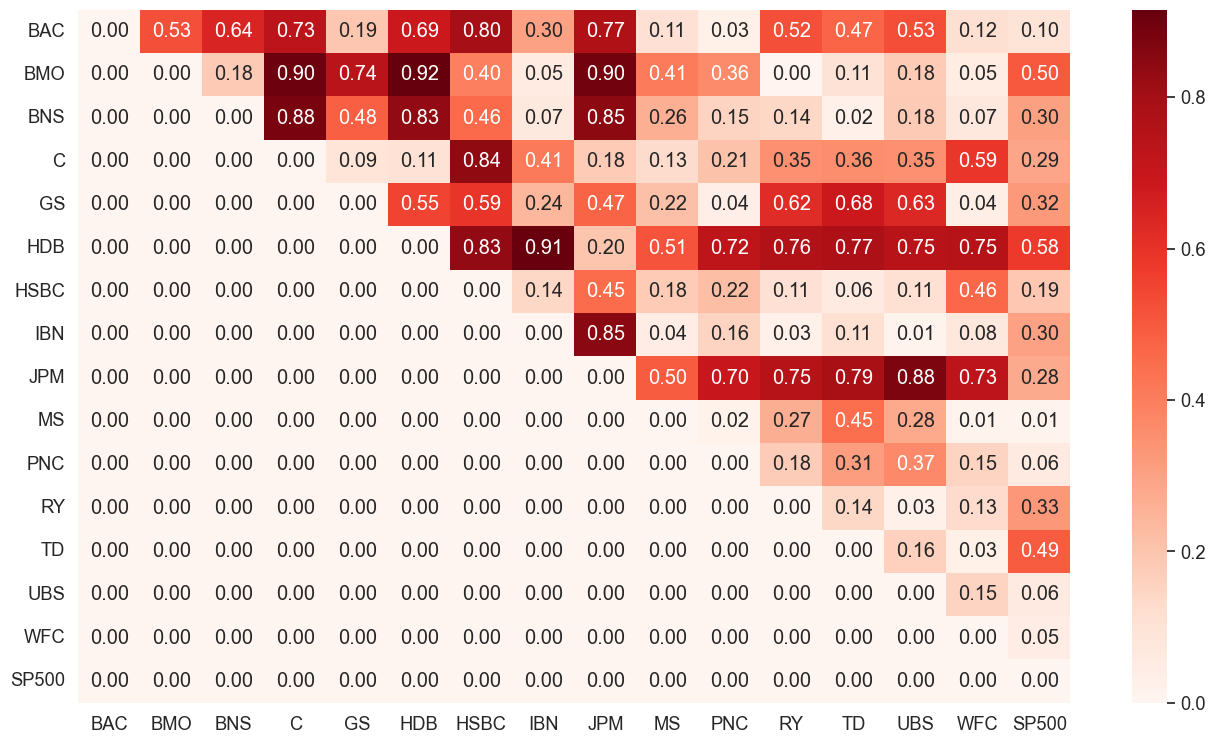

In [4]:
coint_score, pvalue, pairs = find_cointegrated_pairs(df)
label_tickers = list(df.columns)

plt.figure(figsize =(16,9))
sns.set(font_scale =1.2)
sns.heatmap(pvalue,annot= True,cmap = 'Reds', fmt ='0.2f',cbar = True,xticklabels=label_tickers, yticklabels=label_tickers)               
plt.show()

Our first step is to decide the stock universe and identify the pairs with high correlation. It is very important that this is based on economic relationships such as companies with similar businesses, else it might be spurious. We take  constituents of US Financial Sector which are categorized as ‘FINANCIAL SERVICES’ companies. We take the daily closing price for these 15 stocks for from period Jan-20 to Jun-22.

Based on results, we select stocks **BAC(Bank of Americal Copr) and PNC(The PNC Financial Services) as a potential candidate** for cointegration analysis since p -value from cointegraton test is small and less than 0.05 threshold.

# 3 Cointegration Analysis and Mean Reversion process

### 3.1 Stock Prices data

In [5]:
tickers = ['BAC','PNC','SP500']
prices = df[tickers]

train_prices = prices.loc['2020':'2021',:]
test_prices = prices.loc['2022',:]

prices_norm = prices/prices.iloc[0]
train_prices_norm = prices_norm.loc['2020':'2021',:]
test_prices_norm = prices_norm.loc['2022',:]

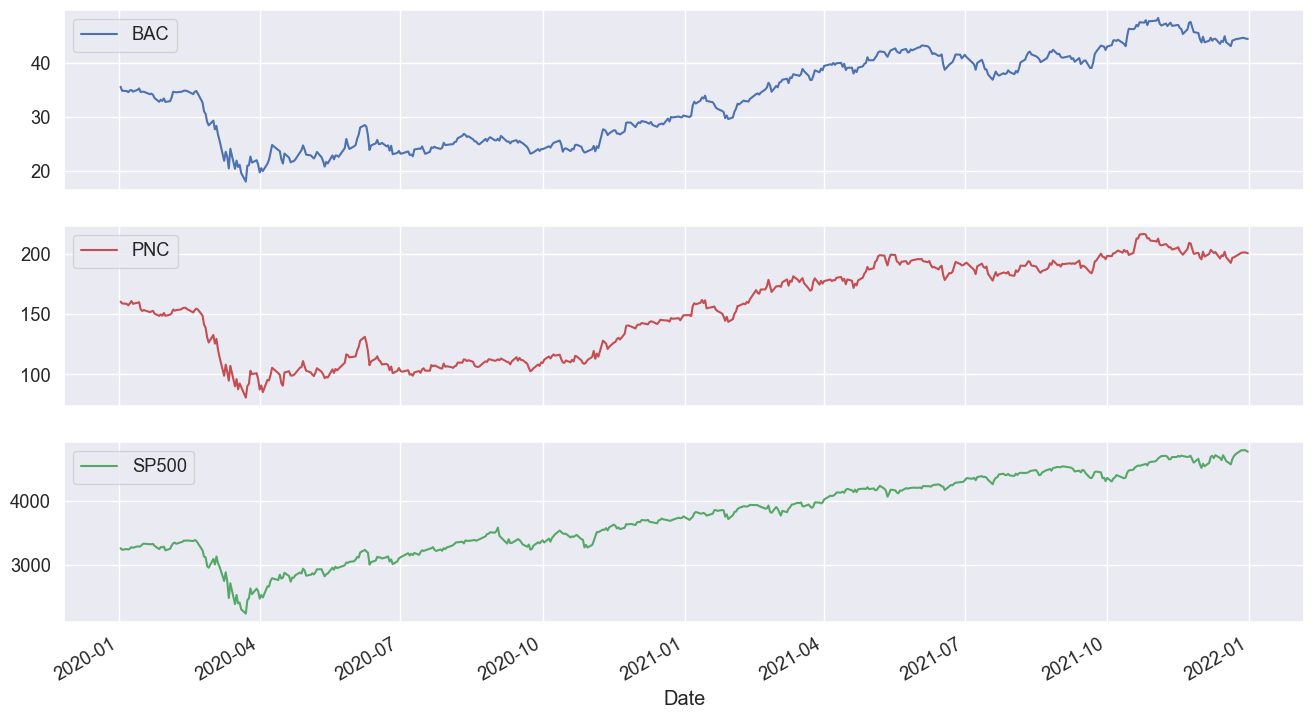

In [6]:
train_prices.plot(figsize=(16,9), color=('b', 'r', 'g'), subplots=True)
plt.show()

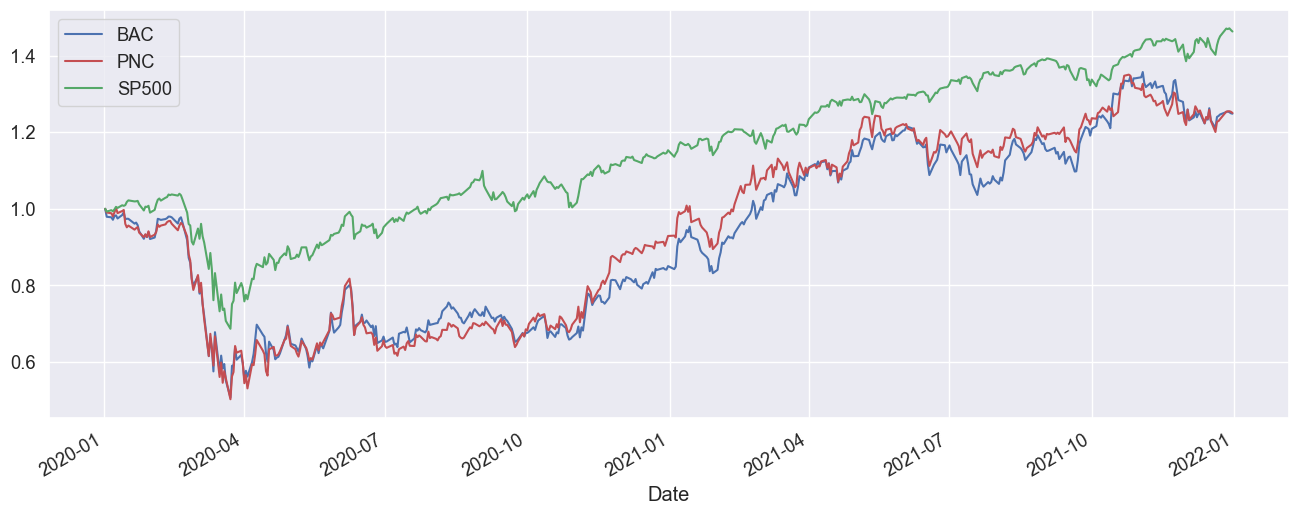

In [7]:
train_prices_norm.plot(figsize=(16,6), color=('b', 'r', 'g'))
plt.show()

We split prices data for BAC and PNC into training and test sets along with S&P 500 index which will be used as a benchmark index for returns comparison & analysis.This is to ensure that our decision to select a cointegrated pair is based on the training dataset and backtesting is done using out of sample test dataset

Time series data are sequential in nature and are characterised by the correlation between observations. Classical cross-validation techniques such as KFold assume the samples are independent and identically distributed, and would result in poor estimates when applied on time series data.

To preserve the order and have training set occur prior to the test set, we split prices data in 80:20 ratio i.e. 80 for training set and 20 for test set sequentially. And therefore training set contains data for 2 years period(Jan-20 to Dec-21) and similarly, test set contains data for 6 months(Jan-22 to Jun-22).

Below are the price charts of BAC, PNC and S&P 500 for training set both in actual and normalized terms i.e. make day 1 prices as unit prices. On Cursory look at these charts, we can say that BAC and PNC prices move together and seem cointegrated. However, we need to perform statistical tests to confirm this hypothesis.

Cointegration testing is sensitive to the initial value(normalising to start at one), also this allows comparison of P&L easily.

### 3.2 Stationarity check fo daily returns 

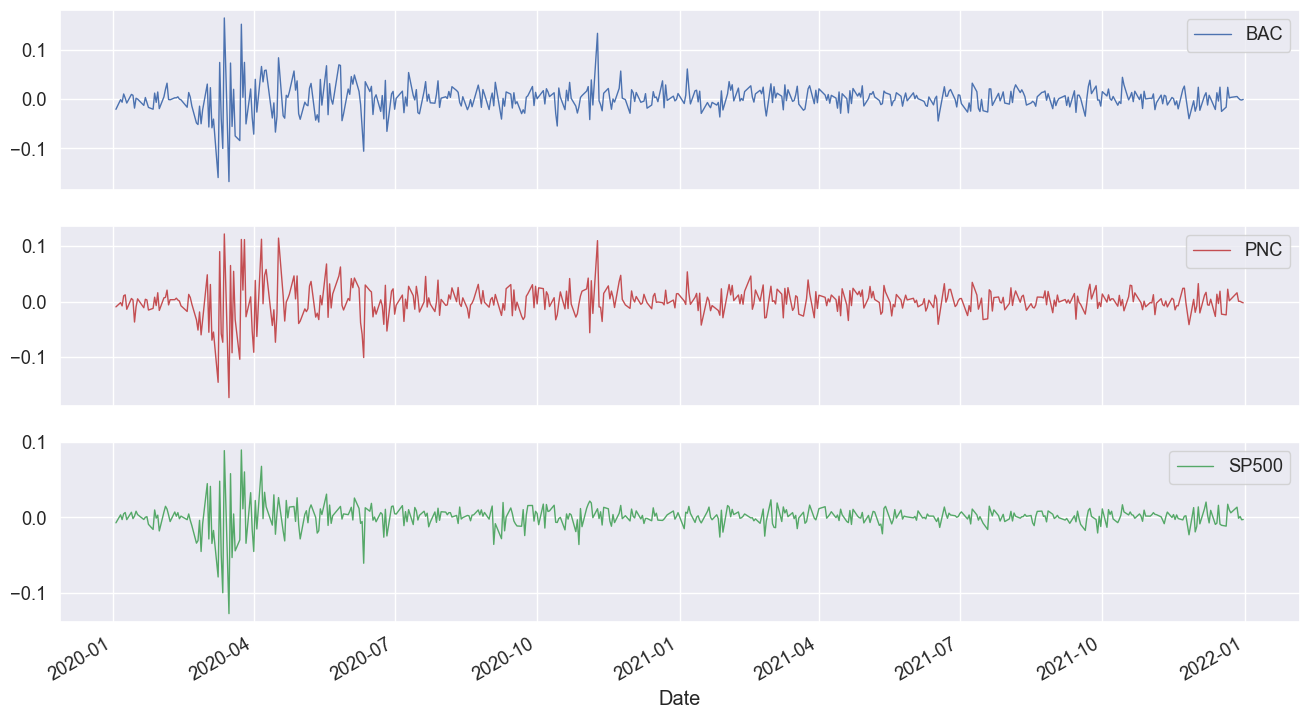

In [8]:
returns = np.log(train_prices).diff().dropna()
returns.plot(figsize=(16,9), color=('b', 'r', 'g'), subplots=True, linewidth=1)
plt.savefig('Latex Report/Figures/returns.png')
plt.show()

From the plots, it seems all three return time series - BAC, PNC and S&P 500 are stationary. However, we will perform Augmented Dickey Fuller(ADF) test to confirm the same. 

### 3.2.1 Stationarity check for BAC log-returns time series - I(0) process

In [9]:
adf_test = adfuller(returns['BAC'])
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-5.933054,0.000000,9,494


From Augmented Dickey-Fuller test output on BAC log-returns time series, we conclude that it is stationary since p-value is insignificant and not breaching ADF distribution threshold. And Hence, BAC log-returns is integrated process of order zero.

### 3.2.2 Stationarity check for PNC stock log-returns time series - I(0) process

In [10]:
adf_test = adfuller(returns['PNC'])
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-6.157858,0.000000,8,495


We perform similar Augmented Dickey-Fuller test on PNC log-returns time series and conclude that it is stationary since p-value is insignificant and not breaching ADF distribution threshold. And Hence, PNC log-returns is integrated process of order zero.

### 3.2.3 Stationarity check for S&P 500 index log-returna time series - I(0) process

In [11]:
adf_test = adfuller(returns['SP500'])
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-6.226686,0.000000,8,495


We perform similar Augmented Dickey-Fuller test on S&P 500 index log-returns time series and conclude that it is stationary since p-value is insignificant and not breaching ADF distribution threshold. And Hence, S&P 500 index log-returns is integrated process of order zero.

### 3.3 VAR Model fitting : Matrix form representation

In [12]:
# BIC test
def var_model_bic(df, p):
    
    bic_values = []
   
    for ar_order in range(1,p+1):
        model = VAR(endog = df)                                   
        fitted_model = model.fit(maxlags = ar_order)
        bic_values.append(fitted_model.bic)
                
    return bic_values

# VAR Model
def var_model(df, p):
    
    model = VAR(endog = df)                                   
    fitted_model = model.fit(maxlags = p)
    return fitted_model

we perform regression between stationary variables which are daily returns of of BAC, PNC and S&P500 stocks. To identify optimal p lags for model selection, we performed BIC test.

In [13]:
var_output_bic = pd.DataFrame({'Lag':list(range(1,11)),'BIC Value':var_model_bic(returns,10)})
var_output_bic

,Lag,BIC Value
0,1,-25.208293
1,2,-25.161105
2,3,-25.113074
3,4,-25.040441
4,5,-24.934885
5,6,-24.866848
6,7,-24.843951
7,8,-24.779945
8,9,-24.723861
9,10,-24.641477


In [14]:
var_output = var_model(returns,1)
var_output.summary()

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Mon, 22, Jan, 2024
Time:                     21:56:40
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -25.2083
Nobs:                     503.000    HQIC:                  -25.2695
Log likelihood:           4236.03    FPE:                1.01964e-11
AIC:                     -25.3090    Det(Omega_mle):     9.95701e-12
--------------------------------------------------------------------
Results for equation BAC
              coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------
const            0.000752         0.001242            0.606           0.545
L1.BAC          -0.046394         0.113398           -0.409           0.682
L1.PNC           0.006555         0.111656            0.059           0.953
L1.SP5

To investigate whether the daily returns depend on their past values, we fit the VAR(1) model to daily returns.

The question now is whether the estimated coefficients are significantly different from zero. We inspect the  p-values. We will reject the hypothesis that a regression coefficient is zero if the corresponding  p-value is less than 5%.

The above output of VAR model conclude that past lagged values cannot be used to predict the future returns for these two equties. Nevertheless, we observe that BAC and PNC stocks retruns are dependent on S&P 500 returns. 

### 3.4 Cointegration Analysis

In this section we implement the Engle-Granger procedure to confirm (or not) if the pair is cointegrated and therefore, suitable for trade design.

### 3.4.1 Engle-Granger Procedure Step 1

### Regression of PNC Financial Services(PNC) stock on Bank of America(BAC) stock 

In [15]:
model = sm.OLS(endog=train_prices_norm['PNC'],exog = sm.add_constant(train_prices_norm['BAC']))           
results = model.fit()     
results.params                              
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    PNC   R-squared:                       0.977
Model:                            OLS   Adj. R-squared:                  0.977
Method:                 Least Squares   F-statistic:                 2.185e+04
Date:                Mon, 22 Jan 2024   Prob (F-statistic):               0.00
Time:                        21:56:40   Log-Likelihood:                 964.25
No. Observations:                 505   AIC:                            -1924.
Df Residuals:                     503   BIC:                            -1916.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0110      0.007     -1.641      0.101      -0.024       0.002
BAC            1.0284      0.007    147.819      0.000       1.015       1.042
==============================================================================
Omnibus:                       18.586   Durbin-Watson:                   0.077
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               13.715
Skew:                           0.298   Prob(JB):                      0.00105
Kurtosis:                       2.456   Cond. No.                         8.27
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

We are now ready to perform the 1st step of the Engle-Granger procedure which is to estimate the model. Here, we do linear regression of PNC prices on BAC prices.

$$ PNC_t = \alpha + \beta * BAC_t + e_t $$
$\alpha = -0.0110, \beta = 1.0284 $ and residual is as follow 

$$ e_t = PNC_t + 0.0110 - 1.0284 * BAC_t $$

where $ \beta_{coint} = [1,-1.0284] $

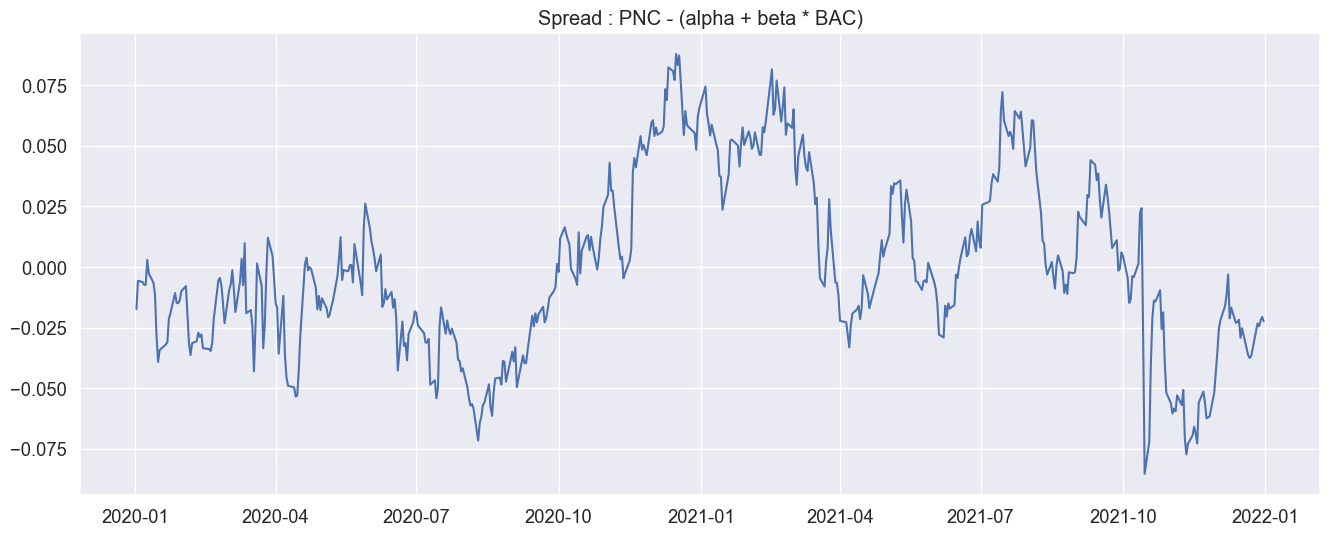

In [16]:
# spread calculation
alpha_PNCBAC = results.params[0]
beta_PNCBAC = results.params[1]
spread_PNC = train_prices_norm['PNC'] - (alpha_PNCBAC + beta_PNCBAC* train_prices_norm['BAC'])

plt.figure(figsize=(16,6))
plt.plot(spread_PNC)
plt.title('Spread : PNC - (alpha + beta * BAC)')
plt.savefig('Latex Report/Figures/spread_pnc.png')
plt.show()

In [17]:
adf_test = adfuller(x = spread_PNC, maxlag = 1, autolag=None)                                          
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-3.223597,0.018659,1,503


$$\Delta e^{PNC}_t = \gamma e^{PNC}_{t-1} + \delta_1 \Delta e^{PNC}_{t-1} + \epsilon_t$$ 

The question now is whether the Cointegrated PNC residual $e^{PNC}_t$ is stationary or not. We perform Augmented Dickey-Fuller Test on this Cointegrated PNC residual (therefore, referred to as CADF) and conclude that it is stationary since p-value is less than 0.05 threshold.

### Regression of Bank of America(BAC) stock on PNC Financial Services(PNC) stock

In [18]:
model = sm.OLS(endog=train_prices_norm['BAC'],exog = sm.add_constant(train_prices_norm['PNC']))           
results = model.fit()     
                            
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    BAC   R-squared:                       0.977
Model:                            OLS   Adj. R-squared:                  0.977
Method:                 Least Squares   F-statistic:                 2.185e+04
Date:                Mon, 22 Jan 2024   Prob (F-statistic):               0.00
Time:                        21:56:41   Log-Likelihood:                 984.15
No. Observations:                 505   AIC:                            -1964.
Df Residuals:                     503   BIC:                            -1956.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0315      0.006      4.996      0.000       0.019       0.044
PNC            0.9505      0.006    147.819      0.000       0.938       0.963
==============================================================================
Omnibus:                        8.373   Durbin-Watson:                   0.077
Prob(Omnibus):                  0.015   Jarque-Bera (JB):                7.338
Skew:                          -0.228   Prob(JB):                       0.0255
Kurtosis:                       2.625   Cond. No.                         8.08
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Here, we do linear regression of BAC prices on PNC prices.

$$ BAC_t = \alpha + \beta * PNC_t + e_t $$
$\alpha = 0.0315, \beta = 0.9505 $ and residual is as follow 

$$ e_t = BAC_t - 0.0315 - 0.9505 * PNC_t $$

where $ \beta_{coint} = [1,-0.9505] $

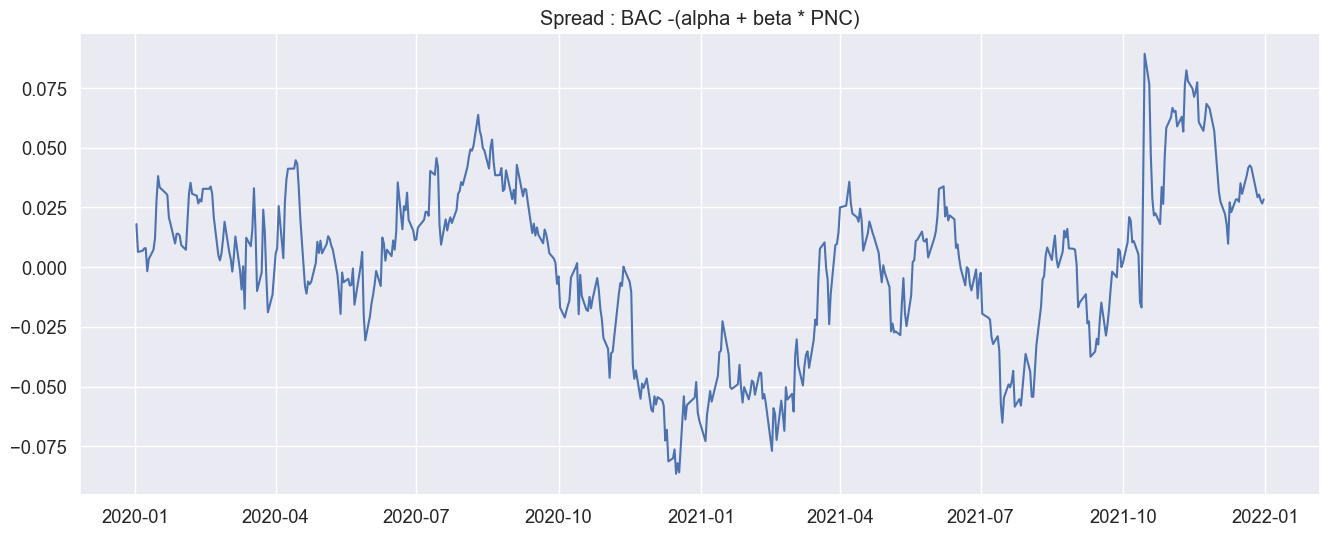

In [19]:
# spread caluclation

alpha_BACPNC = results.params[0]
beta_BACPNC = results.params[1]
spread_BAC = train_prices_norm['BAC'] - (alpha_BACPNC + beta_BACPNC* train_prices_norm['PNC'])

plt.figure(figsize=(16,6))
plt.plot(spread_BAC)
plt.title('Spread : BAC -(alpha + beta * PNC)')
plt.savefig('Latex Report/Figures/spread_bac.png')
plt.show()

In [20]:
adf_test = adfuller(x = spread_BAC, maxlag=1, autolag=None)                                          
columns = ['test statistics','p-value','No of lagged values','No of observations']
adf_output = pd.DataFrame([list(adf_test[0:4])],columns = columns)
dfstyler = adf_output.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

test statistics,p-value,No of lagged values,No of observations
-3.216509,0.019049,1,503


$$\Delta e^{BAC}_t = \gamma e^{BAC}_{t-1} + \delta_1 \Delta e^{BAC}_{t-1} + \epsilon_t$$ 

We perform Augmented Dickey-Fuller Test on this Cointegrated BAC residual $e^{BAC}_t$ and conclude that it is stationary since p-value is less than 0.05 threshold.

### 3.4.2 Engle-Granger Procedure Step 2

### Error correction equation ( PNC on BAC)

In [21]:
X = pd.DataFrame()
X['ΔPrice_BAC'] = train_prices_norm['BAC'].diff(periods =1).dropna()
X['Lag1_Spread_PNC'] = spread_PNC.shift(periods = 1).dropna()

Y = pd.DataFrame()
Y['ΔPrice_PNC'] = train_prices_norm['PNC'].diff(periods = 1).dropna()

model = sm.OLS(endog = Y,exog = X)           
results = model.fit()     

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:             ΔPrice_PNC   R-squared (uncentered):                   0.806
Model:                            OLS   Adj. R-squared (uncentered):              0.805
Method:                 Least Squares   F-statistic:                              1041.
Date:                Mon, 22 Jan 2024   Prob (F-statistic):                   2.35e-179
Time:                        21:56:42   Log-Likelihood:                          1632.6
No. Observations:                 504   AIC:                                     -3261.
Df Residuals:                     502   BIC:                                     -3253.
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
ΔPrice_BAC          0.9057      0.020     45.535      0.000       0.867       0.945
Lag1_Spread_PNC    -0.0294      0.012     -2.471      0.014      -0.053      -0.006
==============================================================================
Omnibus:                       51.017   Durbin-Watson:                   1.933
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              205.857
Skew:                          -0.343   Prob(JB):                     1.99e-45
Kurtosis:                       6.055   Cond. No.                         1.70
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

$$\Delta P^{PNC}_t = \phi \Delta P^{BAC}_{t} - (1-\alpha) \text{Coint_PNCBAC}_{t-1} + \epsilon_t $$

Here we check significance of  $−(1− \alpha)$ term that ensures the correction the long run equilibrium.

In error correction equation the  p-value is evaluated against t-distribution as is common for regression. We will reject  H0
(that a regression coefficient is zero) because the corresponding  p-value is less than 5\%. Above table indicates regression coefficient is significantly different from zero.

We also observe that speed of correction $-(1- \alpha) = -0.0294$ is very small, but is significant for cointegration to exist.

### 3.4.2 Error correction equations(BAC on PNC)

In [22]:
X = pd.DataFrame()
X['ΔPrice_PNC'] = train_prices_norm['PNC'].diff(periods =1).dropna()
X['Lag1_Spread_BAC'] = spread_BAC.shift(periods = 1).dropna()

Y = pd.DataFrame()
Y['ΔPrice_BAC'] = train_prices_norm['BAC'].diff(periods = 1).dropna()

model = sm.OLS(endog = Y,exog = X)           
results = model.fit()     

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:             ΔPrice_BAC   R-squared (uncentered):                   0.808
Model:                            OLS   Adj. R-squared (uncentered):              0.807
Method:                 Least Squares   F-statistic:                              1054.
Date:                Mon, 22 Jan 2024   Prob (F-statistic):                   1.97e-180
Time:                        21:56:42   Log-Likelihood:                          1637.1
No. Observations:                 504   AIC:                                     -3270.
Df Residuals:                     502   BIC:                                     -3262.
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
ΔPrice_PNC          0.8887      0.020     45.484      0.000       0.850       0.927
Lag1_Spread_BAC    -0.0407      0.012     -3.339      0.001      -0.065      -0.017
==============================================================================
Omnibus:                       84.021   Durbin-Watson:                   1.905
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              402.713
Skew:                           0.629   Prob(JB):                     3.56e-88
Kurtosis:                       7.194   Cond. No.                         1.61
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

$$\Delta P^{BAC}_t = \phi \Delta P^{PNC}_{t} - (1-\alpha) \text{Coint_BACPNC}_{t-1} + \epsilon_t$$  

Here we check significance of  $−(1−\alpha)$ term that ensures the correction in long run equilibrium.

In error correction equation the  p-value is evaluated agaist t-distribution as is common for regression. We will reject  H0
(that a regression coefficient is zero) because the corresponding  p-value is less than 5%. Above table indicates regression coefficient is siginificantly different from zero.

We also observe that speed of correction $-(1- \alpha) = -0.0407$ is very small, but is significant for cointegration to exist.

**At the end, we select later case - Error correction equation for BAC on PNC which has better t-statistics as compared to other case.**

### 3.5 OU Process fitting

In [23]:
y = pd.Series(spread_BAC, name = 'BAC Spread')
model = AutoReg(y,lags = 1)                       
fitted_model = model.fit()                                
b =  fitted_model.params[1]
c = fitted_model.params[0]

fitted_model.summary() 

<class 'statsmodels.iolib.summary.Summary'>
"""
                            AutoReg Model Results                             
==============================================================================
Dep. Variable:             BAC Spread   No. Observations:                  505
Model:                     AutoReg(1)   Log Likelihood                1632.090
Method:               Conditional MLE   S.D. of innovations              0.009
Date:                Mon, 22 Jan 2024   AIC                          -3258.179
Time:                        21:56:42   BIC                          -3245.512
Sample:                             1   HQIC                         -3253.210
                                  505                                         
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const          1.839e-05      0.000      0.043      0.965      -0.001       0.001
BAC Spread.L1     0.9618      0.012     78.421      0.000       0.938       0.986
                                    Roots                                    
=============================================================================
                  Real          Imaginary           Modulus         Frequency
-----------------------------------------------------------------------------
AR.1            1.0398           +0.0000j            1.0398            0.0000
-----------------------------------------------------------------------------
"""

above are the details of AR(1) model of BAC Spread(calculated from regression of BAC prices on PNC prices)

In [24]:
tau = 1/252
theta = -np.log(b)/tau
half_life = np.log(2)/theta
SSE = np.sum(fitted_model.resid**2)
T = len(spread_BAC)-1
mu_eq = c/(1-b)
sigma_eq = np.sqrt((SSE/T)/(1-np.exp(-2*theta*tau)))

As we can see half-life is 17.7 days.
The speed of mean-reversion, in this case, is not particularly fast so we might not expect that many trades when implementing the strategy that trades the spread by constructing a long/short portfolio.


In [25]:
columns = ['B','C', 'Half Life','Equilibrium Level','Diffusion']
ou_fitting = pd.DataFrame([[b,c,half_life,mu_eq,sigma_eq]],columns = columns)
dfstyler = ou_fitting.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

B,C,Half Life,Equilibrium Level,Diffusion
0.961767,0.000018,0.070559,0.000481,0.034662


# 4 Trading Strategy

In [26]:
def trading_strategy(df_prices_norm,z_value,alpha, beta,mu_eq,sigma_eq,fee_pct):
    
    # read parameters
    prices_norm = df_prices_norm
    z = z_value
    alpha = alpha
    beta = beta
    mu = mu_eq
    sigma = sigma_eq
    fee_pct = fee_pct
    
    # calculate spread/residual for regression of BAC on PNC  
    spread_BAC = prices_norm['BAC'] - (alpha + beta* prices_norm['PNC'])

    
    df_signal = pd.DataFrame()
    signal_entry = mu + z * sigma
    signal_exit = mu
     
    df_signal['BAC'] = prices_norm['BAC']
    df_signal['PNC'] = prices_norm['PNC']
    df_signal['SP500'] = prices_norm['SP500']  
    df_signal['signal_score'] = spread_BAC 

    # generating trading signals
    df_signal['signal_short_entry'] = (spread_BAC > signal_entry) & (spread_BAC.shift(1) < signal_entry) 
    df_signal['signal_short_exit'] = (spread_BAC < signal_exit) & (spread_BAC.shift(1) > signal_exit) 
    df_signal['signal_long_entry'] = (spread_BAC < -signal_entry) & (spread_BAC.shift(1) > -signal_entry) 
    df_signal['signal_long_exit'] = (spread_BAC > -signal_exit) & (spread_BAC.shift(1) < -signal_exit) 
    
    # computation of trading strategy return along with benchmark(S&P 500) return
    position = 0
    old_position = 0
    counter = -1
    strategy_result = []
    indicator = 0

    for time, signal_stock in  df_signal.iterrows():
        
        counter += 1
        BAC, PNC, SP500 , signal_score,signal_short_entry, signal_short_exit, signal_long_entry, signal_long_exit = signal_stock
        
        # for day 1 seting gross returns, fee, net returns & S&P 500 return as zero
        if counter == 0:
            ret_BAC_gross = 0
            ret_PNC_gross = 0          
            fee = 0
            ret_BAC_net= 0 
            ret_PNC_net= 0
            ret_SP500 = 0
            strategy_result.append([time,position,ret_BAC_gross, ret_PNC_gross, fee, ret_BAC_net, ret_PNC_net,ret_SP500])

        else:      
            if position == 0:
                ret_BAC_gross = 0
                ret_PNC_gross = 0        
                fee = fee_pct*abs(position - old_position)
                ret_BAC_net= ret_BAC_gross - fee
                ret_PNC_net= ret_PNC_gross - fee
                ret_SP500 = (df_signal['SP500'][counter] / df_signal['SP500'][counter-1]) - 1
                strategy_result.append([time,position,ret_BAC_gross, ret_PNC_gross, fee, ret_BAC_net, ret_PNC_net,ret_SP500])

                old_position = position
                
                if signal_short_entry == True:
                    position = -1
                elif signal_long_entry == True:
                    position = 1


            elif position == 1:
                ret_BAC_gross = (df_signal['BAC'][counter] / df_signal['BAC'][counter-1]) - 1
                ret_PNC_gross = -((df_signal['PNC'][counter] / df_signal['PNC'][counter-1]) - 1)                  
                fee = fee_pct*abs(position - old_position)
                ret_BAC_net= ret_BAC_gross - fee
                ret_PNC_net= ret_PNC_gross - fee
                ret_SP500 = (df_signal['SP500'][counter] / df_signal['SP500'][counter-1]) - 1
                strategy_result.append([time,position,ret_BAC_gross, ret_PNC_gross, fee, ret_BAC_net, ret_PNC_net,ret_SP500])

                old_position = position
                
                if signal_long_exit == True:
                    position = 0


            elif position == -1:
                ret_BAC_gross = -((df_signal['BAC'][counter] / df_signal['BAC'][counter-1]) - 1)
                ret_PNC_gross = (df_signal['PNC'][counter] / df_signal['PNC'][counter-1]) - 1
                fee = fee_pct*abs(position - old_position)
                ret_BAC_net= ret_BAC_gross - fee
                ret_PNC_net= ret_PNC_gross - fee
                ret_SP500 = (df_signal['SP500'][counter] / df_signal['SP500'][counter-1]) - 1
                strategy_result.append([time,position,ret_BAC_gross, ret_PNC_gross, fee, ret_BAC_net, ret_PNC_net,ret_SP500])

                old_position = position
                
                if signal_short_exit == True:
                    position = 0
                    

    # collection of P&L data in dataframe
    df_strategy = pd.DataFrame(strategy_result)
    df_strategy.columns = ['Date','Position','Gross BAC Return', 'Gross PNC Return','Fee','Net BAC Return', 'Net PNC Return' ,'SP500 Return']
    df_strategy['n_Trades'] =  np.cumsum(abs(df_strategy['Position'].diff()))
    df_strategy['Gross BAC PL'] = 1* np.cumprod(df_strategy['Gross BAC Return'] + 1)
    df_strategy['Gross PNC PL'] =  beta * np.cumprod(df_strategy['Gross PNC Return'] + 1)
    df_strategy['Net BAC PL'] = 1* np.cumprod(df_strategy['Net BAC Return'] + 1)
    df_strategy['Net PNC PL'] =  beta * np.cumprod(df_strategy['Net PNC Return'] + 1)   
    df_strategy['SP500 PL'] = np.cumprod(df_strategy['SP500 Return'] + 1)
    df_strategy['Gross Strategy PL'] = (df_strategy['Gross BAC PL']  + df_strategy['Gross PNC PL'])
    df_strategy['Gross Strategy PL'] = df_strategy['Gross Strategy PL']/df_strategy['Gross Strategy PL'][0]
    df_strategy['Net Strategy PL'] = (df_strategy['Net BAC PL']  + df_strategy['Net PNC PL'])
    df_strategy['Net Strategy PL'] = df_strategy['Net Strategy PL']/df_strategy['Net Strategy PL'][0]    
    df_strategy['Gross Strategy Return'] = df_strategy['Gross Strategy PL'].pct_change(periods=1)
    df_strategy['Gross Strategy Return'].iloc[0] = 0
    df_strategy['Net Strategy Return'] = df_strategy['Net Strategy PL'].pct_change(periods=1)
    df_strategy['Net Strategy Return'].iloc[0] = 0    
    df_strategy.set_index('Date',drop = True, inplace=True)    

    return df_strategy

### 4.2 Optimization of Z  value based on Cumulative P&L 

In [27]:
z_values = [0.4,0.5,0.6,0.7,0.8,0.9,1,1.1,1.2,1.3,1.4,1.5,1.6]
n_trades = [trading_strategy(train_prices_norm,z,alpha_BACPNC, beta_BACPNC,mu_eq,sigma_eq,0.005)['n_Trades'][-1] for z in z_values ]
strategy_pl = [trading_strategy(train_prices_norm,z,alpha_BACPNC, beta_BACPNC,mu_eq,sigma_eq,0.005)['Net Strategy PL'][-1] for z in z_values]

df_zValues = pd.DataFrame({'Z Values':z_values,'No Trades':n_trades,'Net Strategy PL':strategy_pl})
df_zValues['No Trades'] = df_zValues['No Trades'].astype('int') 
z_optimal = df_zValues.loc[df_zValues['Net Strategy PL'].idxmax() ,'Z Values']
dfstyler = df_zValues.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')

Z Values,No Trades,Net Strategy PL
0.400000,41,1.533095
0.500000,37,1.369339
0.600000,29,1.359928
0.700000,25,1.467668
0.800000,25,1.641601
0.900000,21,1.440361
1.000000,17,1.357221
1.100000,11,1.220459
1.200000,11,1.208968
1.300000,9,1.177141


Based on Strategy cumulative P\&L, we get optimal Z value as 0.8 which has number of trades as 25 including both entry and exit sides.

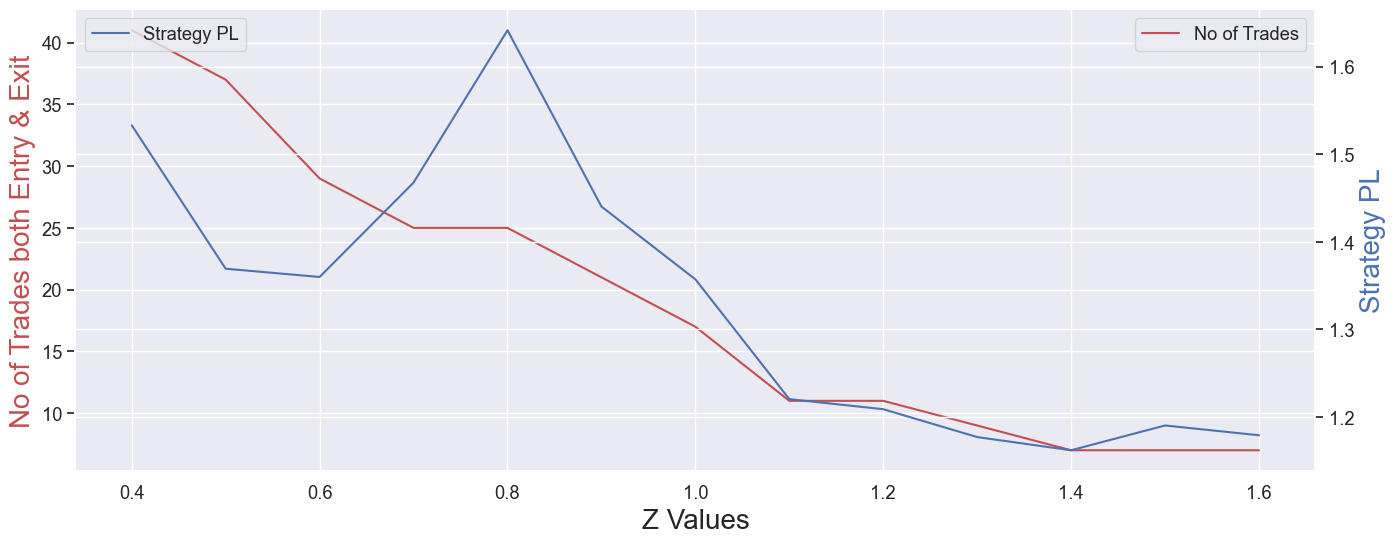

In [28]:
fig, ax1 = plt.subplots(figsize =(16,6))

ax2 = ax1.twinx()
ax1.plot(df_zValues['Z Values'], df_zValues['No Trades'], color = 'r',label = 'No of Trades',)
ax2.plot(df_zValues['Z Values'], df_zValues['Net Strategy PL'], color = 'b',label = 'Strategy PL')
ax1.set_xlabel('Z Values',fontsize = 20)
ax1.set_ylabel('No of Trades both Entry & Exit', color = 'r',fontsize = 20)
ax1.legend(loc='upper right')
ax2.set_ylabel('Strategy PL', color = 'b',fontsize = 20)
ax2.legend(loc='upper left')
plt.savefig('Latex Report/Figures/z_values.png')
plt.show()

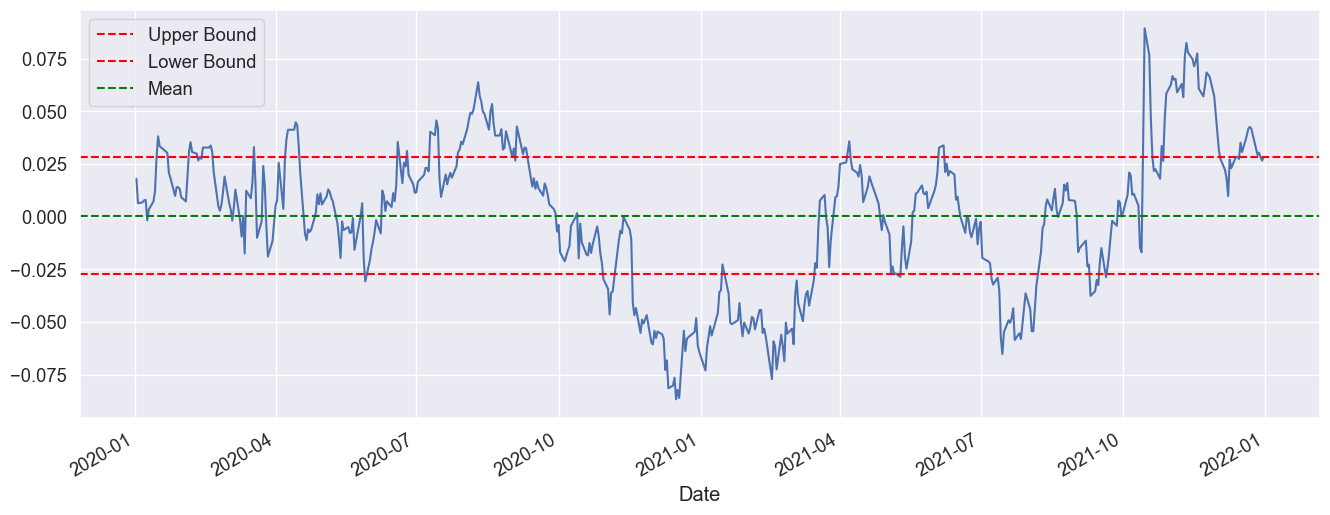

In [29]:
spread_BAC.plot(figsize = (16,6))
plt.axhline(y = mu_eq + z_optimal * sigma_eq,label='Upper Bound', color = 'red',linestyle ='--')   
plt.axhline(y = mu_eq - z_optimal * sigma_eq,label='Lower Bound', color = 'red',linestyle ='--') 
plt.axhline(y = mu_eq ,label='Mean', color = 'green',linestyle ='--') 
plt.legend()
plt.show()

Above plot shows upper bound as 0.0282 and lower bound as -0.0272 with equilibrium level as 0.0005 for trading signals.

### 4.3 Strategy P&L and comparison with Benchmark P&L

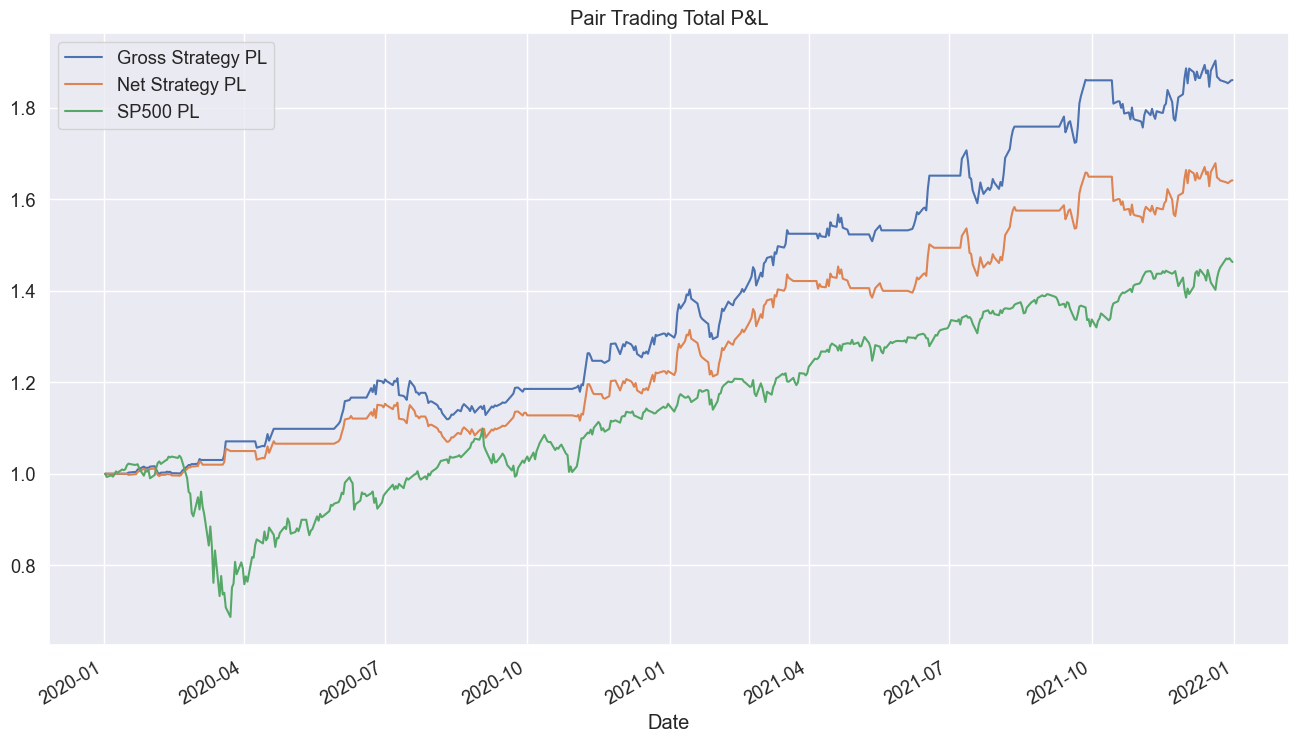

In [30]:
df_strategy_pnl = trading_strategy(train_prices_norm,z_optimal,alpha_BACPNC, beta_BACPNC,mu_eq,sigma_eq,0.005)
df_strategy_pnl[['Gross Strategy PL','Net Strategy PL','SP500 PL']].plot(figsize = (16,9))
plt.title('Pair Trading Total P&L')
plt.show()

# 5 Backtesting of Trading Strategy

### 5.1 Machine learning-inspired Backtesting

For ML based backtesting of trading starategy, we use test dataset which contains stock prices data from Jan-2022 to Jun-2022.

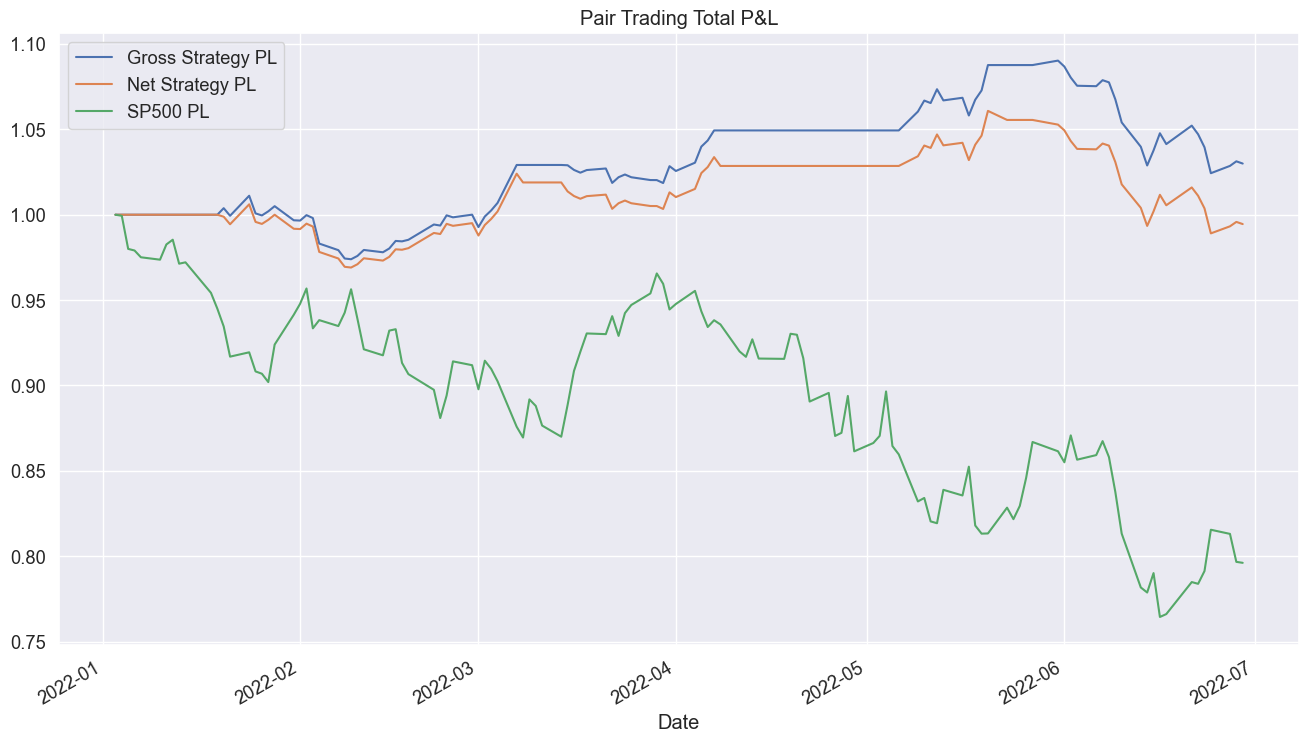

In [31]:
df_backtest_pnl = trading_strategy(test_prices_norm,z_optimal,alpha_BACPNC,beta_BACPNC,mu_eq,sigma_eq,0.005)
df_backtest_pnl[['Gross Strategy PL','Net Strategy PL','SP500 PL']].plot(figsize = (16,9))
plt.title('Pair Trading Total P&L')
plt.show()

### 5.2 Portfolio Risk-Return Analytics

Start date,2022-01-03
End date,2022-06-29
Total months,5
,Backtest
Annual return,-1.1%
Cumulative returns,-0.5%
Annual volatility,8.7%
Sharpe ratio,-0.09
Calmar ratio,-0.17
Stability,0.38
Max drawdown,-6.8%


Worst drawdown periods,Net drawdown in %,Peak date,Valley date,Recovery date,Duration
0,6.76,2022-05-20,2022-06-24,NaT,NaN
1,3.68,2022-01-24,2022-02-09,2022-03-07,31
2,2.02,2022-03-07,2022-03-30,2022-04-05,22
3,1.43,2022-05-12,2022-05-17,2022-05-20,7
4,0.56,2022-01-19,2022-01-21,2022-01-24,4


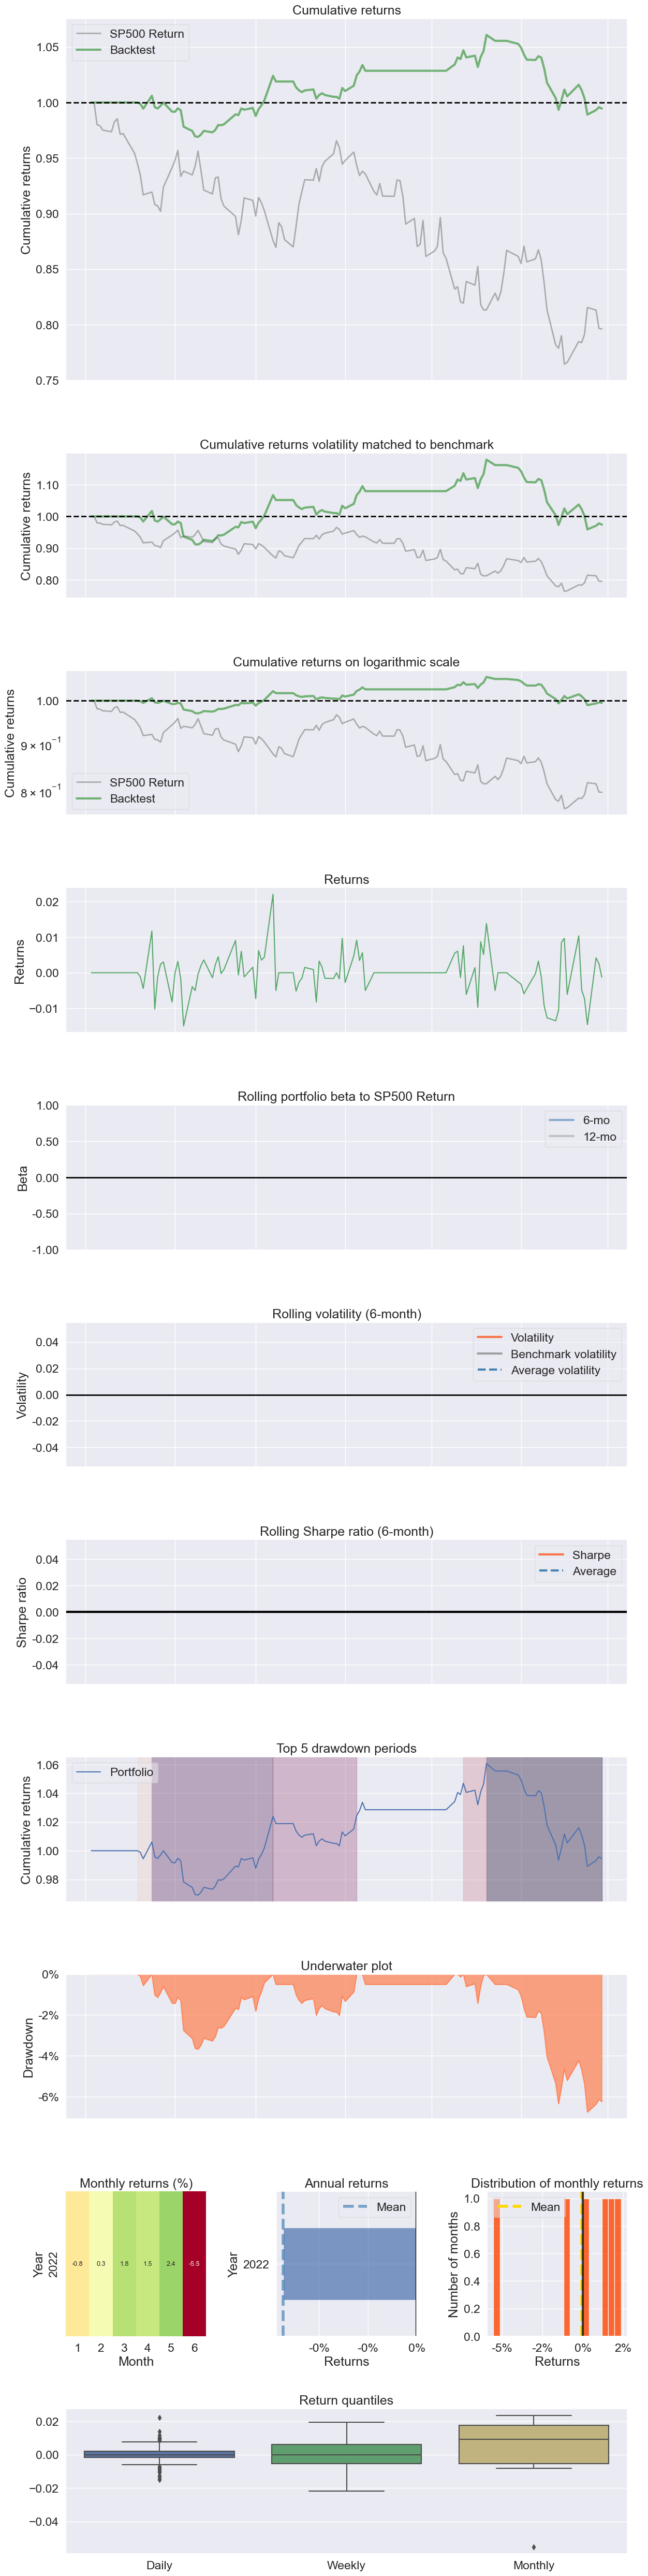

In [32]:
pf.create_returns_tear_sheet(df_backtest_pnl['Net Strategy Return'], benchmark_rets = df_backtest_pnl['SP500 Return'])

### 5.3 Rolling Sharpe

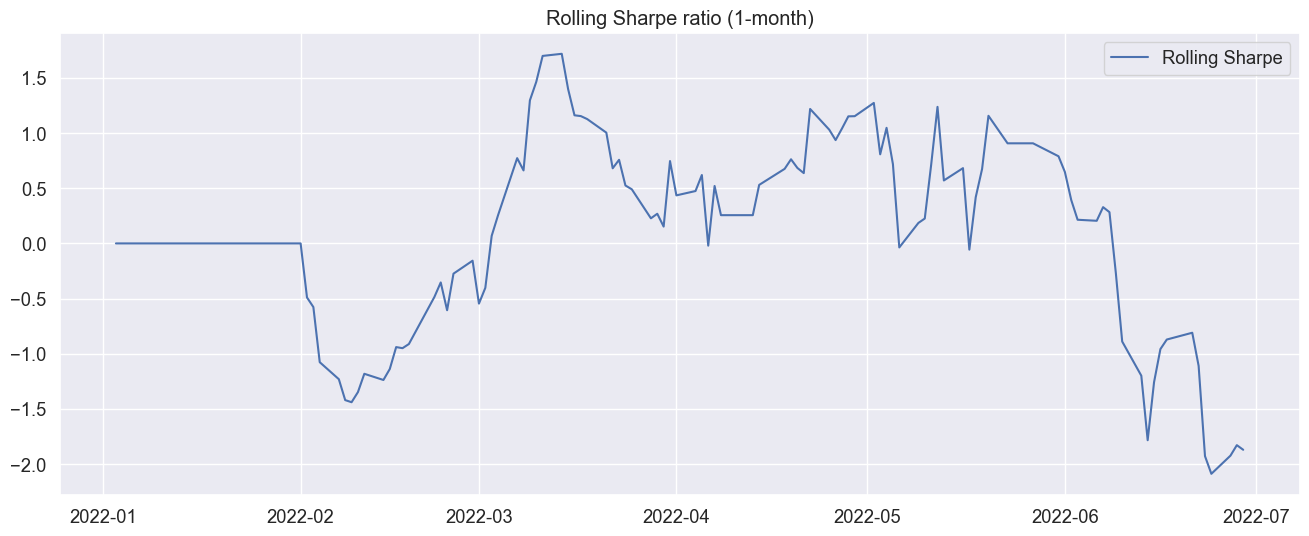

In [33]:
# number of trading days in 1 Month window
window = 22

# 1 Year US Treasury bill rate  - 4.8%
r_f = 0.0002    

def rolling_sharpe(returns,window,r_f):
    return np.sqrt(window) * ((returns.mean() - r_f) / returns.std())

rolling_shapre = df_backtest_pnl['Net Strategy Return'].rolling(window = window).apply(rolling_sharpe,args = (window,r_f))   
rolling_shapre.fillna(0,inplace = True)
plt.figure(figsize = (16,6))
plt.plot(rolling_shapre, label = 'Rolling Sharpe')
plt.legend(loc='best')
plt.title('Rolling Sharpe ratio (1-month)')
plt.show()

### 5.4 Rolling Beta

In [34]:
# number of trading days in 1 Month window
window = 22

# 1 Year US Treasury bill rate  - 4.8%
r_f = 0.0002    
   

def rolling_beta(df,window):
    
    n_obs = df.shape[0]
    beta = np.full(n_obs, np.NaN)
    
    for t in range(window-1, n_obs):
        model = LinearRegression()   
        X = (df['Net Strategy Return'][t-window+1:t+1] - r_f).to_frame()
        y = df['SP500 Return'][t-window+1:t+1] - r_f
        model.fit(X = X, y= y)         
        beta[t]  = model.coef_[0]                                        
    
    return beta

rolling_beta = rolling_beta(df_backtest_pnl,window)

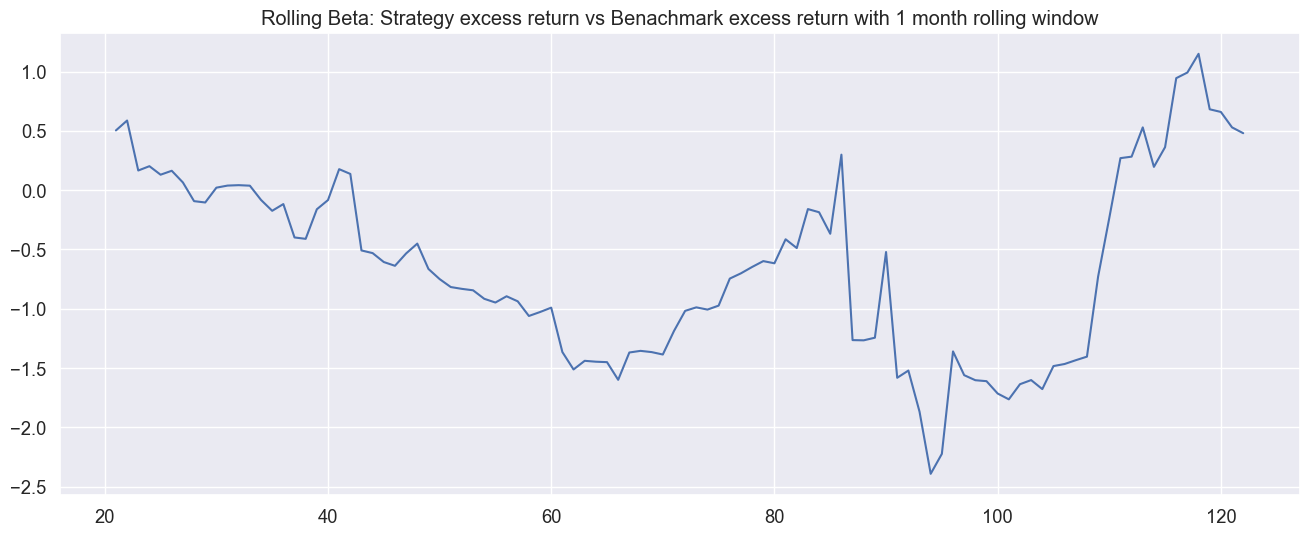

In [35]:
plt.figure(figsize = (16,6))
plt.plot(rolling_beta)
plt.title("Rolling Beta: Strategy excess return vs Benachmark excess return with 1 month rolling window")
plt.show()

In [36]:
#-----------------END OF CODE---------------------------------------------------------------------------